# 08 — Evaluación de hipótesis

## Objetivo

Evaluar formalmente las tres hipótesis del proyecto. Para cada una se informan
el test, el **tamaño del efecto**, un **intervalo de confianza** (bootstrap,
2.000 réplicas, semilla fija) y una prueba de **robustez**, además del p-valor.

**Cambio respecto de la versión anterior.** La primera versión copiaba a mano
los resultados de la notebook 04 sin volver a calcularlos. Ahora todos los tests
se recalculan acá desde `data/processed/`, y H3 se evalúa con el modelo
económico corregido de la notebook 07.

Se usan tests no paramétricos, porque el USD/m² y el precio relativo son
asimétricos y tienen colas pesadas (notebook 04). Se evalúan varias pruebas, por
lo que se usa un nivel de 1 % como referencia más exigente que el 5 %.

In [1]:
# Entorno: ubicar la raíz del repositorio (la carpeta que contiene src/)
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import BASE_FEATURES, PROCESSED_DIR, MIN_COMPARABLES, MARGEN_MINIMO_PCT

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)
N_BOOT = 2000

df = pd.read_csv(BASE_FEATURES)
df["Precio_Relativo_pct"] = -df["Gap_Subvaluacion_pct"]
print("Avisos:", len(df))


def ic_bootstrap(x, y, estad=lambda a, b: np.median(a) - np.median(b), n=N_BOOT):
    """IC 95 % percentil del estadístico, remuestreando cada grupo por separado."""
    x, y = np.asarray(x), np.asarray(y)
    reps = [estad(rng.choice(x, len(x)), rng.choice(y, len(y))) for _ in range(n)]
    return np.percentile(reps, [2.5, 97.5])


def comparar(x, y, nombre, alternativa="less", relativa=False):
    """Mann-Whitney + diferencia de medianas + probabilidad de superioridad + IC."""
    x, y = pd.Series(x).dropna(), pd.Series(y).dropna()
    u, p = stats.mannwhitneyu(x, y, alternative=alternativa)
    if relativa:
        est = lambda a, b: (np.median(a) - np.median(b)) / np.median(b) * 100
    else:
        est = lambda a, b: np.median(a) - np.median(b)
    lo, hi = ic_bootstrap(x, y, est)
    return {"Comparación": nombre, "n1": len(x), "n2": len(y),
            "Diferencia de medianas": round(est(x.values, y.values), 1),
            "IC 95 %": f"[{lo:.1f}; {hi:.1f}]",
            "P(grupo 1 < grupo 2)": round(1 - u / (len(x) * len(y)), 3),
            "p-valor": f"{p:.1e}"}

Avisos: 9499


## H1 — Descuento por condición

> Los departamentos que necesitan obra presentan un USD/m² menor que los
> reciclados o en buen estado, aun dentro de un mismo estrato.

- **Comparación directa:** USD/m² de `Necesita_obra` contra `Reciclada_refaccionada`
  (diferencia de medianas en %).
- **Comparación controlada:** precio relativo al benchmark del estrato (barrio,
  ambientes, superficie y antigüedad), `Necesita_obra` contra `Buen_o_reciclada`
  (diferencia en puntos porcentuales). Es la prueba relevante para H1, porque
  compara cada aviso con sus comparables.
- **Robustez:** se repite la comparación controlada sin los avisos con señal de
  estado contradictoria y solo con los estratos de nivel 1 o 2 (los más finos).

La probabilidad de superioridad es la probabilidad de que una unidad que
necesita obra, elegida al azar, esté más barata que una del otro grupo
(0,5 = sin diferencia).

In [2]:
obra = df["Estado_Propiedad"].eq("Necesita_obra")
recic = df["Estado_Propiedad"].eq("Reciclada_refaccionada")
bueno = df["Estado_Agrupado"].eq("Buen_o_reciclada")
no_contra = ~df["Flag_Senal_Contradictoria"].fillna(False).astype(bool)
fino = df["Nivel_Benchmark"].isin([1, 2])
rel = df["Precio_Relativo_pct"]

h1 = pd.DataFrame([
    comparar(df.loc[obra, "USD_m2_Homogeneizado"], df.loc[recic, "USD_m2_Homogeneizado"],
             "Directa: USD/m² (%), obra vs. reciclada", relativa=True),
    comparar(rel[obra], rel[bueno], "Controlada: precio relativo (pp), obra vs. buen/reciclada"),
    comparar(rel[obra & no_contra], rel[bueno & no_contra], "Robustez: sin señales contradictorias"),
    comparar(rel[obra & fino], rel[bueno & fino], "Robustez: solo estratos de nivel 1 y 2"),
])
display(h1)

,Comparación,n1,n2,Diferencia de medianas,IC 95 %,P(grupo 1 < grupo 2),p-valor
0,"Directa: USD/m² (%), obra vs. reciclada",439,977,-25.4,[-30.2; -22.2],0.757,2.4e-54
1,"Controlada: precio relativo (pp), obra vs. buen/reciclada",435,3010,-17.5,[-19.9; -15.3],0.747,1.1e-62
2,Robustez: sin señales contradictorias,368,3000,-16.4,[-18.4; -14.5],0.737,3.1e-50
3,Robustez: solo estratos de nivel 1 y 2,369,2501,-17.3,[-19.4; -15.2],0.754,3.6e-56


Kruskal-Wallis entre 12 comunas (≥ 10 avisos a reciclar): H = 13.50, p = 0.262, épsilon² = 0.006


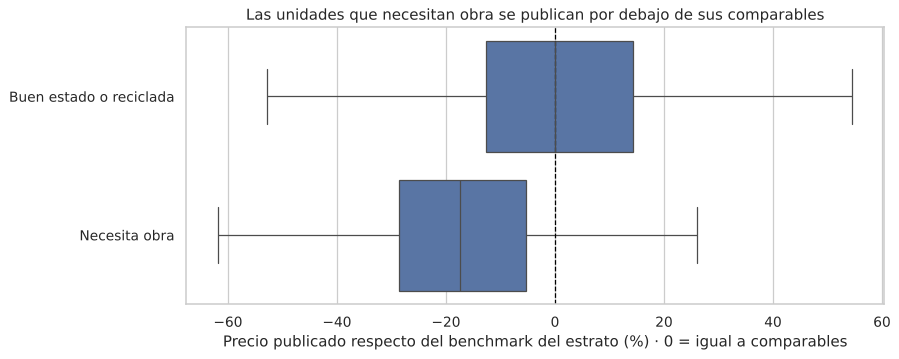

In [3]:
# Heterogeneidad: ¿el descuento es similar entre comunas?
grupos = [g["Precio_Relativo_pct"].dropna().values
          for _, g in df[obra].groupby("Comuna") if g["Precio_Relativo_pct"].notna().sum() >= 10]
h, p_kw = stats.kruskal(*grupos)
n_kw = sum(len(g) for g in grupos)
epsilon2 = (h - len(grupos) + 1) / (n_kw - len(grupos))
print(f"Kruskal-Wallis entre {len(grupos)} comunas (≥ 10 avisos a reciclar): "
      f"H = {h:.2f}, p = {p_kw:.3f}, épsilon² = {max(epsilon2, 0):.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
datos = df[(obra | bueno) & rel.between(-80, 120)].assign(
    Grupo=lambda d: np.where(d["Estado_Propiedad"].eq("Necesita_obra"), "Necesita obra", "Buen estado o reciclada"))
sns.boxplot(data=datos, x="Precio_Relativo_pct", y="Grupo", showfliers=False, ax=ax)
ax.axvline(0, color="black", ls="--", lw=1)
ax.set(title="Las unidades que necesitan obra se publican por debajo de sus comparables",
       xlabel="Precio publicado respecto del benchmark del estrato (%) · 0 = igual a comparables", ylabel="")
plt.show()

**Resultado H1: se sostiene.** El descuento es estadísticamente significativo,
su intervalo de confianza no incluye el cero y se mantiene al excluir las
señales contradictorias y al usar solo los estratos más finos. No difiere de
forma relevante entre comunas (el épsilon² es muy bajo). El modelo hedónico de
la notebook 10, que controla por amenities y otras características, estima un
descuento algo menor (≈ 14 % frente a buen estado), coherente con este
resultado.

**Relevancia práctica.** El descuento es real, pero su magnitud es moderada. La
notebook 07 muestra que no alcanza para pagar una obra media o integral (ver H3).

## H2 — Dispersión condicional

> Una mayor dispersión del USD/m² dentro de un estrato homogéneo indica
> oportunidades, una vez descartados los errores de carga.

Estratos: barrio × ambientes × banda de superficie, con al menos 10 avisos.
Dispersión relativa = rango intercuartílico / mediana. Se mide la correlación
de Spearman entre la dispersión del estrato y su proporción de propiedades
baratas.

**Explicación alternativa.** Un estrato puede ser disperso porque tiene errores
de carga. Por eso se repite el análisis contando solo las baratas sin
indicadores de error (`Barata`) y se mide también la correlación con las que
requieren verificación.

Estratos analizados: 289


,rho,IC 95 %,p-valor
Todas las baratas,0.477,[0.37; 0.57],8.5e-18
Solo baratas sin indicadores de error,0.433,[0.33; 0.53],1.3e-14
Baratas que requieren verificación,0.277,[0.18; 0.37],1.7e-06


Spearman parcial (baratas sin error vs. dispersión, controlando tamaño del estrato): 0.451


,Estratos,Avisos,% baratas sin error,% requieren verificación
Quintil,,,,
Q1 menos disperso,58.0,1052.0,3.3,0.2
Q2,58.0,1847.0,4.2,0.6
Q3,57.0,1571.0,7.3,0.9
Q4,58.0,1864.0,8.7,1.2
Q5 más disperso,58.0,1884.0,10.1,1.5


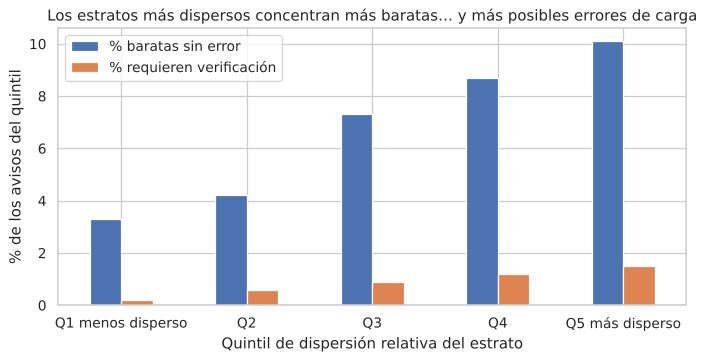

In [4]:
estrato = ["Barrio_Oficial", "Ambientes_Grupo", "Banda_Superficie"]
clas = df["Clasificacion_Oportunidad"].fillna("")
e = (df.assign(Barata_total=clas.str.startswith("Barata"),
               Barata_limpia=clas.eq("Barata"),
               Verificacion=clas.eq("Barata_requiere_verificacion"))
     .groupby(estrato, observed=True)
     .agg(N=("USD_m2_Homogeneizado", "size"),
          Mediana=("USD_m2_Homogeneizado", "median"),
          IQR=("USD_m2_Homogeneizado", lambda x: x.quantile(.75) - x.quantile(.25)),
          Pct_baratas=("Barata_total", "mean"),
          Pct_baratas_limpias=("Barata_limpia", "mean"),
          Pct_verificacion=("Verificacion", "mean")))
e = e[e["N"] >= MIN_COMPARABLES].copy()
e["Dispersion_relativa"] = e["IQR"] / e["Mediana"]


def spearman_ic(x, y, n=N_BOOT):
    x, y = np.asarray(x), np.asarray(y)
    rho, p = stats.spearmanr(x, y)
    idx = [rng.integers(0, len(x), len(x)) for _ in range(n)]
    reps = [stats.spearmanr(x[i], y[i])[0] for i in idx]
    lo, hi = np.nanpercentile(reps, [2.5, 97.5])
    return {"rho": round(rho, 3), "IC 95 %": f"[{lo:.2f}; {hi:.2f}]", "p-valor": f"{p:.1e}"}


h2 = pd.DataFrame({
    "Todas las baratas": spearman_ic(e["Dispersion_relativa"], e["Pct_baratas"]),
    "Solo baratas sin indicadores de error": spearman_ic(e["Dispersion_relativa"], e["Pct_baratas_limpias"]),
    "Baratas que requieren verificación": spearman_ic(e["Dispersion_relativa"], e["Pct_verificacion"]),
}).T
print("Estratos analizados:", len(e))
display(h2)

# Control por tamaño del estrato: correlación parcial (rangos) controlando N
r = e[["Dispersion_relativa", "Pct_baratas_limpias", "N"]].rank()
res = lambda col: r[col] - np.polyval(np.polyfit(r["N"], r[col], 1), r["N"])
rho_parcial = np.corrcoef(res("Dispersion_relativa"), res("Pct_baratas_limpias"))[0, 1]
print(f"Spearman parcial (baratas sin error vs. dispersión, controlando tamaño del estrato): {rho_parcial:.3f}")

e["Quintil"] = pd.qcut(e["Dispersion_relativa"], 5, labels=["Q1 menos disperso", "Q2", "Q3", "Q4", "Q5 más disperso"])
quint = (e.groupby("Quintil", observed=True)
         .apply(lambda g: pd.Series({"Estratos": len(g), "Avisos": g["N"].sum(),
                                     "% baratas sin error": (g["Pct_baratas_limpias"] * g["N"]).sum() / g["N"].sum() * 100,
                                     "% requieren verificación": (g["Pct_verificacion"] * g["N"]).sum() / g["N"].sum() * 100}))
         .round(1))
display(quint)

fig, ax = plt.subplots(figsize=(9, 4))
quint[["% baratas sin error", "% requieren verificación"]].plot.bar(ax=ax, rot=0)
ax.set(title="Los estratos más dispersos concentran más baratas… y más posibles errores de carga",
       xlabel="Quintil de dispersión relativa del estrato", ylabel="% de los avisos del quintil")
plt.show()

**Resultado H2: se sostiene parcialmente.** La asociación entre dispersión y
oportunidades es positiva y significativa, y se mantiene al contar solo las
baratas sin indicadores de error y al controlar por el tamaño del estrato. Pero
los estratos más dispersos también concentran más casos que requieren
verificación. La dispersión sirve como **señal para priorizar la revisión**, no
como evidencia de oportunidad por sí sola. Es una asociación entre estratos y
no permite afirmar que la dispersión cause las oportunidades.

## H3 — Existencia de oportunidades de flipping

> En una parte de los casos que necesitan obra, el descuento de entrada supera
> el costo de refacción, los costos de transacción, la tenencia y las
> contingencias, con margen positivo aun en el escenario conservador.

Se evalúa con el modelo económico corregido de la notebook 07, que usa los
supuestos con fuente de `data/supuestos_flipping.csv`. Se informa la proporción
de unidades rentables en cada escenario, con un intervalo de Wilson al 95 %.

In [5]:
flip = pd.read_csv(PROCESSED_DIR / "flipping_modelo_economico.csv")

def wilson(k, n, z=1.96):
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    radio = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - radio, centro + radio

filas = []
for esc in ["Conservador", "Base", "Optimista"]:
    for umbral, etiqueta in [(0, "ROI > 0"), (MARGEN_MINIMO_PCT, f"ROI ≥ {MARGEN_MINIMO_PCT} %")]:
        k = int((flip[f"ROI_{esc}_pct"] > umbral).sum()) if umbral == 0 else int((flip[f"ROI_{esc}_pct"] >= umbral).sum())
        lo, hi = wilson(k, len(flip))
        filas.append({"Escenario": esc, "Criterio": etiqueta, "Unidades": k, "n": len(flip),
                      "%": round(k / len(flip) * 100, 1), "IC 95 % (Wilson)": f"[{lo*100:.1f} %; {hi*100:.1f} %]"})
h3 = pd.DataFrame(filas)
display(h3)
display(flip["Decision"].value_counts().to_frame("Unidades"))
print("ROI base mediano:", round(flip["ROI_Base_pct"].median(), 1), "%")
print("Obra máxima pagable (mediana):", round(flip["Obra_Max_Pagable_USD_m2"].median()), "USD/m²")

,Escenario,Criterio,Unidades,n,%,IC 95 % (Wilson)
0,Conservador,ROI > 0,0,428,0.0,[0.0 %; 0.9 %]
1,Conservador,ROI ≥ 15 %,0,428,0.0,[0.0 %; 0.9 %]
2,Base,ROI > 0,2,428,0.5,[0.1 %; 1.7 %]
3,Base,ROI ≥ 15 %,0,428,0.0,[0.0 %; 0.9 %]
4,Optimista,ROI > 0,62,428,14.5,[11.5 %; 18.1 %]
5,Optimista,ROI ≥ 15 %,16,428,3.7,[2.3 %; 6.0 %]


,Unidades
Decision,
Descartar,427
Revisar manualmente,1


ROI base mediano: -38.8 %
Obra máxima pagable (mediana): 24 USD/m²


**Resultado H3: no se sostiene.** Con los supuestos con fuente, ninguna unidad
es rentable en el escenario conservador; incluso el límite superior del
intervalo de confianza es bajo. En el escenario base, la proporción rentable es
marginal. La sensibilidad de la notebook 07 muestra que el resultado solo cambia
si la obra fuera liviana en todos los casos, lo que no es consistente con la
evidencia del texto de los avisos.

H3 se reformula como un hallazgo: **el descuento de las unidades a reciclar
alcanza para cubrir los costos de transacción y de tenencia, pero no el de una
obra media o integral.** La herramienta útil para el fondo es el precio máximo
de oferta de cada unidad.

## Síntesis

In [6]:
sintesis = pd.DataFrame({
    "Hipótesis": ["H1 — Descuento por condición", "H2 — Dispersión condicional", "H3 — Flipping rentable"],
    "Evidencia principal": [
        f"Precio relativo {h1.loc[1, 'Diferencia de medianas']} pp vs. buen estado/reciclada, IC {h1.loc[1, 'IC 95 %']}",
        f"Spearman {h2.loc['Solo baratas sin indicadores de error', 'rho']} (baratas sin error), IC {h2.loc['Solo baratas sin indicadores de error', 'IC 95 %']}",
        f"{h3.loc[0, 'Unidades']} de {h3.loc[0, 'n']} rentables en el conservador; {h3.loc[2, 'Unidades']} en el base",
    ],
    "Robustez": ["Se mantiene sin señales contradictorias y en estratos finos",
                 "Se mantiene sin errores y controlando por tamaño; más dispersión también implica más errores",
                 "Solo cambia con obra liviana generalizada"],
    "Estado": ["Se sostiene", "Se sostiene parcialmente", "No se sostiene (reformulada)"],
})
display(sintesis)

,Hipótesis,Evidencia principal,Robustez,Estado
0,H1 — Descuento por condición,"Precio relativo -17.5 pp vs. buen estado/reciclada, IC [-19.9; -15.3]",Se mantiene sin señales contradictorias y en estratos finos,Se sostiene
1,H2 — Dispersión condicional,"Spearman 0.433 (baratas sin error), IC [0.33; 0.53]",Se mantiene sin errores y controlando por tamaño; más dispersión también implica más errores,Se sostiene parcialmente
2,H3 — Flipping rentable,0 de 428 rentables en el conservador; 2 en el base,Solo cambia con obra liviana generalizada,No se sostiene (reformulada)
